<table style="width: 100%;">
  <tr>
    <td style="text-align: left; vertical-align: middle;">
        <h1 style="margin: 0;">Deep Learning's Assignment 4</h1>
        <h4 style="margin: 0;">Prof. Bahrak</h4>
        <h4 style="margin: 0;">Authors: Erfan Ahmadi, Mohammad Ali Olama</h4>
        <h4 style="margin: 0;">[Group work]</h4>
    </td>
    <td style="text-align: right; vertical-align: middle;">
      <img src="https://media.porsline.ir/images/1642313491sktwifppujekhvh" alt="CC" width="1000">
    </td>
  </tr>
</table>



# Question 1

## Libraries and imports


In [ ]:
!pip install torch transformers peft datasets accelerate scipy bitsandbytes wandb  -qqq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 68.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 36.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 55.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 18.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 93.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.1/76.1 MB 10.2 MB/s eta 0:00:00


In [ ]:

!huggingface-cli login --token YOUR_HF_TOKEN

The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `huggingface-cli` if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `LLM-HW1` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
The current active token is: `LLM-HW1`


In [ ]:
!pip install trl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.0/348.0 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 12.1 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.2
    Uninstalling fsspec-2025.3.2:
      Successfully uninstalled fsspec-2025.3.2
  Attempting uninstall: datasets
    Found existing installation: datasets 2.14.4
    Uninstalling datasets-2.14.4:
      Successfully uninstalled datasets-2.14.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.2 requires fsspec==2025.3.2, but you have fsspec 2025.3.0 which is incompatible.


In [ ]:
import torch
import numpy as np
import re
import time
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
from collections import defaultdict
from datasets import load_dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer,AutoModelForCausalLM

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Set seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

## Constant variables
to make the code more readable, we define constant variables that will be used across the code in this Config class:

In [ ]:
class CONFIG:
    seed = 42
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

device = CONFIG.device

In [ ]:
device

device(type='cuda')

In [ ]:
# get torch random seed

print(torch.initial_seed())

42


## Q1.1



**Transformer Architecture**

BERT is based on the Transformer encoder architecture introduced by Vaswani et al. (2017). It consists of multiple layers of self-attention and feedforward networks. BERTBASE uses 12 layers, 768 hidden units, and 12 attention heads, while BERTLARGE uses 24 layers, 1024 hidden units, and 16 attention heads.

![q](https://towardsdatascience.com/wp-content/uploads/2024/05/16Vy32tUuqtAwz24CfS83wg-1-1024x652.png)

![s](https://towardsdatascience.com/wp-content/uploads/2024/05/1Qww2aaIdqrWVeNmo3AS0ZQ-2048x1314.png)

A key innovation of BERT is its deep bidirectionality. Unlike left-to-right models (e.g., GPT) or shallow bidirectional models, BERT attends to both left and right context in all layers using the self-attention mechanism.

Each token in the input can attend to all other tokens in the sequence, enabling the model to learn complex contextual relationships.

![a](https://towardsdatascience.com/wp-content/uploads/2024/05/1otV3y8jKM_zSxA-0YiLi1w-1-2048x1504.png)
---

**Input Representation**

BERT’s input representation is constructed by summing three types of embeddings:

- **Token Embeddings**: BERT uses WordPiece embeddings to handle rare and subword tokens.
- **Segment Embeddings**: To distinguish between two sentences in tasks like question answering or next sentence prediction, BERT adds segment embeddings (Sentence A or Sentence B).
- **Position Embeddings**: These are added to represent the position of each token in the sequence since the transformer architecture is position-agnostic.

BERT also uses special tokens:
- `[CLS]` is placed at the beginning of every input sequence and is used for classification tasks.
- `[SEP]` is used to separate different segments (sentences).

![b](https://towardsdatascience.com/wp-content/uploads/2024/05/1w4r6Hz2IF-Uvo4YHg2-bCw-1-1024x328.png)
---

**Pretraining Objectives**

BERT is pretrained using two self-supervised learning tasks:

- **Masked Language Modeling (MLM)**: Randomly masks 15% of the input tokens. Of these, 80% are replaced with `[MASK]`, 10% with a random token, and 10% are left unchanged. The model is trained to predict the original token for each masked position.

- **Next Sentence Prediction (NSP)**: Given two input sentences, the model predicts whether the second sentence logically follows the first. 50% of the time, the second sentence is the actual next sentence (labeled *IsNext*), and 50% of the time it is a random sentence (labeled *NotNext*). The `[CLS]` token’s final representation is used for this binary classification task.


## Q1.2

Let's download the dataset first.

In [ ]:
!git clone https://github.com/AUT-NLP/PQuAD.git

# make folder if not exists '/content/Data'
!mkdir -p /content/Data
!cp PQuAD/Dataset/* /content/Data
!rm -rf PQuAD

Cloning into 'PQuAD'...
remote: Enumerating objects: 27, done.
remote: Counting objects: 100% (27/27), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 27 (delta 9), reused 15 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (27/27), 5.71 MiB | 6.69 MiB/s, done.
Resolving deltas: 100% (9/9), done.


There is an info.txt file which describes this dataset.

In [ ]:
with open('/content/Data/readme_pquad_en.txt', 'r') as f:
    print(f.read())

PQuAD is a crowd- sourced reading comprehension dataset on Persian Language. It includes 80,000 
questions along with their answers, with 25% of the questions being unanswerable. As a reading 
comprehension dataset, it requires a system to read a passage and then answer the given questions 
from the passage. PQuAD's questions are based on Persian Wikipedia articles and cover a wide 
variety of subjects. Articles used for question generation are quality checked and include few 
number of non-Persian words. 

The dataset is divided into three categories including train, validation, and test sets and the 
statistics of these sets are as follows:

+----------------------------+-------+------------+------+-------+
|                            | Train | Validation | Test | Total |
+----------------------------+-------+------------+------+-------+
|      Total Questions       | 63994 |    7976    | 8002 | 79972 |
|   Unanswerable Questions   | 15721 |    1981    | 1914 | 19616 |
| Mean # of p

Now, let's load the datasets

In [ ]:
import pandas as pd


train_df = pd.read_json('/content/Data/Train.json')
test_df = pd.read_json('/content/Data/Test.json')
valid_df = pd.read_json('/content/Data/Validation.json') # Use dev for validation as per standard practice
print("Datasets loaded successfully into pandas DataFrames.")
print("Train DataFrame shape:", train_df.shape)
print("Test DataFrame shape:", test_df.shape)
print("Validation DataFrame shape:", valid_df.shape)

Datasets loaded successfully into pandas DataFrames.
Train DataFrame shape: (891, 2)
Test DataFrame shape: (114, 2)
Validation DataFrame shape: (120, 2)


In [ ]:
# Display first few rows of each dataframe
print("\nTrain DataFrame head:")
train_df.head()



Train DataFrame head:


,version,data
0,c1,"{'title': 'آرسنال', 'paragraphs': [{'qas': [{'..."
1,c1,"{'title': 'فوتبال', 'paragraphs': [{'qas': [{'..."
2,c1,"{'title': 'سیارک', 'paragraphs': [{'qas': [{'q..."
3,c1,"{'title': 'کلاس‌بندی خودروها', 'paragraphs': [..."
4,c1,"{'title': 'چین', 'paragraphs': [{'qas': [{'que..."


The 'data' column is a json string. let's print a sample to see the structure.

In [ ]:
import json

data = train_df['data'][0]
data_json = json.loads(json.dumps(data)) # Convert Python dict/list to JSON string and then load it
data_json


{'title': 'آرسنال',
 'paragraphs': [{'qas': [{'question': 'موقعیت جغرافی باشگاه فوتبال آرسنال را بگویید؟',
     'id': '101001',
     'answers': [{'text': 'شمال شهر لندن', 'answer_start': 86}],
     'is_impossible': False},
    {'question': 'لیگ برتر انگلستان موفق به کسب چند عنوان قهرمانی در جام حذفی فوتبال انگلستان شده است؟',
     'id': '101002',
     'answers': [{'text': '۱۴', 'answer_start': 173}],
     'is_impossible': False},
    {'question': 'بیشترین بازی بدون باخت پیاپی متعلق به کدام باشگاه است؟',
     'id': '101003',
     'answers': [{'text': 'باشگاه فوتبال انگلیسی', 'answer_start': 61}],
     'is_impossible': False},
    {'question': 'باشگاه فوتبال آرسنال موفق به کسب چند عنوان قهرمانی در لیگ دسته اول شد؟',
     'id': '101004',
     'answers': [{'text': '۱۳', 'answer_start': 119}],
     'is_impossible': False},
    {'question': 'باشگاه فوتبال آرسنال چند عنوان قهرمانی در جام خیریه انگلستان را کسب کرد؟',
     'id': '101005',
     'answers': [{'text': '۱۶', 'answer_start': 214}],
 

It is a JSON file with the following hierarchical structure:

- **data**: A list of articles.
  - **title**: *(string)* The topic of the article.
  - **paragraphs**: A list of paragraph objects.
    - **context**: *(string)* The paragraph or passage text.
    - **qas**: A list of question-answer pairs.
      - **id**: *(string)* Unique identifier for the question.
      - **question**: *(string)* The question text.
      - **answers**: A list of answers.
        - **text**: *(string)* The answer text.
        - **answer_start**: *(int)* Character index of the answer in the context.
      - **is_impossible**: *(bool)* Indicates if the question is unanswerable based on the context.

This structure supports both answerable and unanswerable questions, suitable for extractive QA tasks.


Now, let's flatten this structure! We've borrowed a code from a github repository for this task:

In [ ]:
# DISCLAIMER: This cell is borrowed from a github repository. Slight modifications are applied.

def json_to_dataframe(data):
    # f = open ( file , "r")
    # data = json.loads(f.read())               #loading the json file.
    iid = []
    tit = []                                  #Creating empty lists to store values.
    con = []
    Que = []
    Ans_st = []
    Txt = []
    Is_impossible = []

    for i in range(len(data['data'])):       #Root tag of the json file contains 'title' tag & 'paragraphs' list.
        title = data['data'][i]['title']
        for p in range(len(data['data'][i]['paragraphs'])):  # 'paragraphs' list contains 'context' tag & 'qas' list.
            context = data['data'][i]['paragraphs'][p]['context']
            for q in range(len(data['data'][i]['paragraphs'][p]['qas'])):  # 'qas' list contains 'question', 'Id' tag & 'answers' list.
                question = data['data'][i]['paragraphs'][p]['qas'][q]['question']
                Id = data['data'][i]['paragraphs'][p]['qas'][q]['id']
                is_impossible = data['data'][i]['paragraphs'][p]['qas'][q]['is_impossible']
                if len(data['data'][i]['paragraphs'][p]['qas'][q]['answers']) == 0 :
                  ans_start = -1
                  text = ''
                  tit.append(title)
                  con.append(context)
                  Que.append(question)                    # Appending values to lists
                  iid.append(Id)
                  Ans_st.append(ans_start)
                  Txt.append(text)
                  Is_impossible.append(True)
                else :
                  for a in range(len(data['data'][i]['paragraphs'][p]['qas'][q]['answers'])): # 'answers' list contains 'ans_start', 'text' tags.
                      ans_start = data['data'][i]['paragraphs'][p]['qas'][q]['answers'][a]['answer_start']
                      text = data['data'][i]['paragraphs'][p]['qas'][q]['answers'][a]['text']
                      is_impossible = data['data'][i]['paragraphs'][p]['qas'][q]['is_impossible']

                      tit.append(title)
                      con.append(context)
                      Que.append(question)                    # Appending values to lists
                      iid.append(Id)
                      Ans_st.append(ans_start)
                      Txt.append(text)
                      Is_impossible.append(is_impossible)

    new_df = pd.DataFrame(columns=['Id','title','context','question','ans_start','text' , 'is_impossible']) # Creating empty DataFrame.
    new_df.Id = iid
    new_df.title = tit           #intializing list values to the DataFrame.
    new_df.context = con
    new_df.question = Que
    new_df.ans_start = Ans_st
    new_df.text = Txt
    new_df.is_impossible = Is_impossible

    final_df = new_df.drop_duplicates(keep='first')  # Dropping duplicate rows from the create Dataframe.
    return final_df


df_train = json_to_dataframe(train_df)
train_rows = df_train.shape[0]
print('size of Train dataframe before concatenation is {}'.format(train_rows))

df_test = json_to_dataframe(test_df)
df_validation = json_to_dataframe(valid_df)


# frames = [df_train, df_validation]
# df_train = pd.concat(frames)
# train_rows = df_train.shape[0]
# print('size of Train dataframe after concatenation is {}'.format(train_rows))
df_train.head()

size of Train dataframe before concatenation is 63994


,Id,title,context,question,ans_start,text,is_impossible
0,101001,آرسنال,باشگاه فوتبال آرسنال (به انگلیسی: Arsenal Foo...,موقعیت جغرافی باشگاه فوتبال آرسنال را بگویید؟,86,شمال شهر لندن,False
1,101002,آرسنال,باشگاه فوتبال آرسنال (به انگلیسی: Arsenal Foo...,لیگ برتر انگلستان موفق به کسب چند عنوان قهرمان...,173,۱۴,False
2,101003,آرسنال,باشگاه فوتبال آرسنال (به انگلیسی: Arsenal Foo...,بیشترین بازی بدون باخت پیاپی متعلق به کدام باش...,61,باشگاه فوتبال انگلیسی,False
3,101004,آرسنال,باشگاه فوتبال آرسنال (به انگلیسی: Arsenal Foo...,باشگاه فوتبال آرسنال موفق به کسب چند عنوان قهر...,119,۱۳,False
4,101005,آرسنال,باشگاه فوتبال آرسنال (به انگلیسی: Arsenal Foo...,باشگاه فوتبال آرسنال چند عنوان قهرمانی در جام ...,214,۱۶,False


In [ ]:
df_impossible_sample = df_train[df_train['is_impossible'] == True].head(1)
df_impossible_sample


,Id,title,context,question,ans_start,text,is_impossible
11,101062,آرسنال,باشگاه فوتبال آرسنال در سال ۱۸۸۶ در محله وول‌...,آرسنال با کدام کشور رقابت دارد؟,-1,,True


### Data analysis

In [ ]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63994 entries, 0 to 63993
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Id             63994 non-null  object
 1   title          63994 non-null  object
 2   context        63994 non-null  object
 3   question       63994 non-null  object
 4   ans_start      63994 non-null  int64 
 5   text           63994 non-null  object
 6   is_impossible  63994 non-null  bool  
dtypes: bool(1), int64(1), object(5)
memory usage: 3.0+ MB


In [ ]:
print("\nValue counts for 'title' in df_train:")
df_train['title'].value_counts()


Value counts for 'title' in df_train:


,count
title,
باشگاه اتلتیکو مادرید,362
باشگاه فوتبال اینترناتسیوناله میلانو,325
امپراتوری روم,307
نهنگ,296
دلفین,266
...,...
سینمای آمریکا,7
انتخابات مجلس شورای اسلامی ایران,5
چهره‌های ماندگار,5


In [ ]:
print("\nValue counts for 'is_impossible' in df_train:")
df_train['is_impossible'].value_counts()


Value counts for 'is_impossible' in df_train:


,count
is_impossible,
False,48273
True,15721


In [ ]:

print("\nValue counts for 'context' in df_train (top 10):")
df_train['context'].value_counts()


Value counts for 'context' in df_train (top 10):


,count
context,
ده‌ها برندهٔ جایزهٔ نوبل دیگر نیز بوده‌اند که یا مانند پروفسور زلتن اسپرانتو را فراگرفته‌اند و از آن در تألیفات خود استفاده کرده‌اند؛ مانند جوزف تامسون (برندهٔ نوبل فیزیک در سال ۱۹۰۶)، دانیل باوِت (نوبل پزشکی در سال ۱۹۵۷)، ایزاک بشویس سینگر (نوبل ادبیات در سال ۱۹۷۸)؛ یا اسپرانتو را فراگرفته و در تحسین و توصیهٔ آن زبان گشوده‌اند؛ مثل ویلهِلم اُستوالد (نوبل شیمی در سال ۱۹۰۹)، رابیندرانات تاگور (نوبل ادبیات در سال ۱۹۱۳)، و پروفسور لینوس پائولینگ (نوبل شیمی در سال ۱۹۵۴ و نوبل صلح در سال ۱۹۶۲)؛ یا با اسپرانتو آشنائی داشتند و استفاده از آن را به مردم جهان توصیه کرده‌اند؛ همانند: ویلیام رَمزی (نوبل شیمی در سال ۱۹۰۴)، بِرتا فون سوتنِر (نوبل صلح در سال ۱۹۰۵)، سِلما لاگِرلوف (نوبل ادبیات در سال ۱۹۰۹)، هنری لافونتِن (نوبل صلح در سال ۱۹۱۳)، رومن رولان (نوبل ادبیات در سال ۱۹۱۵)، فریتیوف نانسن (نوبل صلح در سال ۱۹۲۲)، هیدکی یوکاوا (نوبل فیزیک در سال ۱۹۴۹)، برتراند راسل (نوبل ادبیات در سال ۱۹۵۰)، یاروسلاو هیروفسکی (نوبل شیمی در سال ۱۹۵۹)، آلفرد کاستلر (نوبل فیزیک در سال ۱۹۶۶)، ویلی برانت (نوبل صلح در سال ۱۹۷۱)، و ...,72
در سال ۲۰۰۵ هفده کشور اکسیدهای اورانیوم غلیظ تولید کردند: کانادا(۲۹٫۷٪ از تولید جهانی)، استرالیا(۲۲٫۸٪)، قزاقستان(۱۰٫۵٪)، روسیه(۸٫۰٪)، نامیبیا(۷٫۵٪)، نیجر(۷٫۴٪)، ازبکستان(۵٫۵٪)، ایالات متحده(۲٫۵٪)، آرژانتین(۲٫۱٪)، اوکراین(۱٫۹٪) و چین(۱٫۷٪). قزاقستان همچنان به افزایش تولید خود ادامه می‌دهد و احتمالاً با تولید پیش‌بینی شده ۱۲۸۲۶ تن در مقایسه با کانادا با ۱۱۱۰۰ تن و استرالیا با ۹۴۳۰ تن به بزرگ‌ترین تولیدکننده اورانیوم در جهان در سال ۲۰۰۹ تبدیل شده‌است. در اواخر دهه ۱۹۶۰، زمین شناسان سازمان ملل هم چنین ذخایر مهم اورانیوم و سایر ذخایر معدنی کمیاب در سومالی را کشف کردند. این یافته در نوع خود بزرگ‌ترین بود، به طوری که کارشناسان صنعت بیش از ۲۵٪ ذخایر اورانیوم شناخته شده در جهان را ۸۰۰۰۰۰ تن تخمین زده‌اند.,43
باشگاه فوتبال تاتنهام هاتسپر (به انگلیسی: Tottenham Hotspur Football Club) که بیشتر با نام‌های تاتنهام یا اِسپرز شناخته می‌شود، یک باشگاه حرفه‌ای فوتبال در لیگ برتر انگلستان است که در منطقه تاتنهام در شمال شهر لندن، در کشور انگلستان قرار دارد. دو بار موفق به قهرمانی در لیگ انگلستان درسال‌های ۱۹۵۰–۵۱ و ۱۹۶۰–۶۱ شده‌است. از آوریل سال ۲۰۱۹، این تیم بازی‌های خانگی‌اش را در ورزشگاه تاتنهام هاتسپر برگزار می‌کند؛ پیش از این، ورزشگاه وایت هارت لین محل برگزاری بازی‌های خانگی تاتنهام بود که به منظور ساخت ورزشگاه جدید در همین مکان، تخریب شد. زمین تمرین آنها در هاتسپر وی در بولز کراس در منطقه انفیلد لندن است. این باشگاه متعلق به گروه انیک است. لباس اول تیم تاتنهام شامل پیراهن سفید و شورت سرمه‌ای است؛ این ترکیب رنگی از فصل ۹۹–۱۸۹۸ تا کنون مورد استفاده قرار می‌گیرد. نشان برجسته و نماد باشگاه، یک خروس است که بر روی یک توپ فوتبال قرار گرفته‌است؛ هم‌چنین شعار «To Dare Is to Do» به معنی «شهامت انجام دادنش رو داریم»، شعار مشهور و اصلی هواداران این تیم است.,36
بدشانسی‌های اینتر در فصل بعد نیز ادامه پیدا کرد ، اینتر درحالی که با گل خرید جدید خود رابی کین در دیدار سوپر جام فوتبال ایتالیا در سال ۲۰۰۰ از لاتزیو پیش افتاده بود ، در نهایت با نتیجه چهار بر سه مغلوب حریف خود شد و به مقام نایب قهرمانی رسید ، همچین اینتر با شکست در مرحله سوم مسابقات پلی آف برابر تیم سوئدی هلسینگبورگس نتوانست جواز حضور در مرحله گروهی لیگ قهرمانان اروپا فصل ۰۲-۲۰۰۱ را کسب کند . لیپی پس از شکست در اولین بازی فصل جدید برابر رجینا که اولین شکست تاریخ باشگاه برابر این تیم بود ، اخراج شد . مارکو تاردلی به عنوان جانشین لیپی انتخاب شد ، اما تاردلی هم نتوانست نتایج خوبی را کسب کند و هواداران اینتر ، تاردلی را به عنوان سرمربی که دربی شهر میلان را شش بر صفر در برابر تیم میلان واگذار کرد به یاد می‌آورند .,34
خلافت راشدین (به عربی: الخلافة الراشدة) یا خلافت اولیه نخستین حکومت اسلامی تحت نام خلافت است که در روز درگذشت محمد پیامبر اسلام، در دوشنبه ۲۸ صفر سال ۱۱ ه‍. ق[ه. ق 1] برابر با ۱۰ ژوئن سال ۶۳۲میلادی پدید آمد. و تا سال ۴۰ هجری به طول انجامید. فرمانروایان از صحابه محمد و از طایفه قریش به ترتیب ابوبکر (حاکم ۶۳۲–۶۳۴)، عمر بن خطاب (حاکم ۶۳۴–۶۴۴)، عثمان بن عفان (حاکم ۶۴۴–۶۵۶) و علی بن ابی‌طالب (حاکم ۶۵۶–۶۶۱) بودند. اهل سنت که منزلت دینی ویژه‌ای برای حاکمان این حکومت قائلند حکومتشان را خلافت راشدین[پانویس 1] به معنای «خلافت هدایت شده» می‌نامند، اما آنان که مشرو


Statistics for title length:
count    63994.000000
mean        10.858034
std          6.304197
min          2.000000
25%          6.000000
50%         10.000000
75%         14.000000
max         47.000000
Name: title_len, dtype: float64

Statistics for context length:
count    63994.000000
mean       690.782386
std        182.487780
min         51.000000
25%        563.000000
50%        671.000000
75%        811.000000
max       1520.000000
Name: context_len, dtype: float64

Statistics for question length:
count    63994.000000
mean        54.675485
std         26.052209
min          8.000000
25%         37.000000
50%         50.000000
75%         67.000000
max        359.000000
Name: question_len, dtype: float64

Statistics for answer length:
count    63994.000000
mean        21.014501
std         36.917979
min          0.000000
25%          2.000000
50%          9.000000
75%         22.000000
max        825.000000
Name: answer_len, dtype: float64


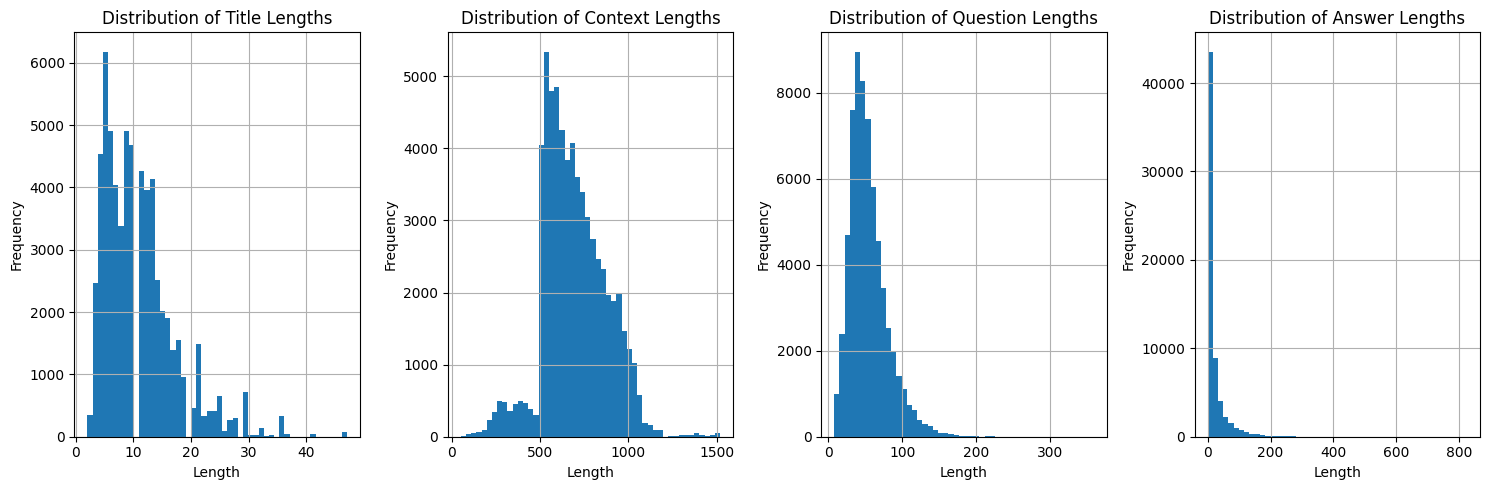

In [ ]:
def statistics(df):
  # clone df
  df_copy = df.copy()
  # Calculate the length of 'title','context', 'question', and 'text' columns
  df_copy['title_len'] = df_copy['title'].apply(len)
  df_copy['context_len'] = df_copy['context'].apply(len)
  df_copy['question_len'] = df_copy['question'].apply(len)
  df_copy['answer_len'] = df_copy['text'].apply(len)

  # Print descriptive statistics for lengths
  print("\nStatistics for title length:")
  print(df_copy['title_len'].describe())

  print("\nStatistics for context length:")
  print(df_copy['context_len'].describe())

  print("\nStatistics for question length:")
  print(df_copy['question_len'].describe())

  print("\nStatistics for answer length:")
  print(df_copy['answer_len'].describe())



  # Optionally, visualize the distributions
  plt.figure(figsize=(15, 5))

  plt.subplot(1, 4, 1)
  df_copy['title_len'].hist(bins=50)
  plt.title('Distribution of Title Lengths')
  plt.xlabel('Length')
  plt.ylabel('Frequency')

  plt.subplot(1, 4, 2)
  df_copy['context_len'].hist(bins=50)
  plt.title('Distribution of Context Lengths')
  plt.xlabel('Length')
  plt.ylabel('Frequency')

  plt.subplot(1, 4, 3)
  df_copy['question_len'].hist(bins=50)
  plt.title('Distribution of Question Lengths')
  plt.xlabel('Length')
  plt.ylabel('Frequency')

  plt.subplot(1, 4, 4)
  df_copy['answer_len'].hist(bins=50)
  plt.title('Distribution of Answer Lengths')
  plt.xlabel('Length')
  plt.ylabel('Frequency')

  plt.tight_layout()
  plt.show()

statistics(df_train)

### Q1.2.1


Load BertTokenizer

In [ ]:
from transformers import AutoTokenizer, BertTokenizer

# Load the BERT tokenizer
tokenizer_parsbert = AutoTokenizer.from_pretrained("HooshvareLab/bert-base-parsbert-uncased")
tokenizer_albert = AutoTokenizer.from_pretrained("m3hrdadfi/albert-fa-base-v2")

# Example
text = "This is a sample sentence to tokenize."
encoded_input_parsbert = tokenizer_parsbert(text, return_tensors='pt') # return_tensors='pt' gives PyTorch tensors
encoded_input_albert = tokenizer_albert(text, return_tensors='pt') # return_tensors='pt' gives PyTorch tensors

print("Original text:", text)
print(60 * "=")
print("Encoded input:", encoded_input_parsbert)
print("Tokens:", tokenizer_parsbert.convert_ids_to_tokens(encoded_input_parsbert['input_ids'][0]))
print(60 * "-")
print("Encoded input:", encoded_input_albert)
print("Tokens:", tokenizer_albert.convert_ids_to_tokens(encoded_input_albert['input_ids'][0]))

Original text: This is a sample sentence to tokenize.
Encoded input: {'input_ids': tensor([[    2, 47701, 11684,    29, 17605, 46588, 87541, 21229, 11725, 88051,
         54316,    15,     4]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}
Tokens: ['[CLS]', 'this', 'is', 'a', 'sam', '##ple', 'sent', '##ence', 'to', 'token', '##ize', '.', '[SEP]']
------------------------------------------------------------
Encoded input: {'input_ids': tensor([[    2,    11, 30589, 17312,  2674,    11, 71546, 12813,  2734, 41602,
         37126, 10002,    11, 43047, 48184,     7,     3]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])}
Tokens: ['[CLS]', '▁', 'this', '▁is', '▁a', '▁', 'samp', 'le', '▁s', 'ent', 'ence', '▁to', '▁', 'token', 'ize', '.', '[SEP]']


### Q1.2.2

Embeddings are inside the model itself!

###Q1.2.3
This part will be implemented completely later. For now, let's implement a sample code to contacting query and context:

In [ ]:
sample_context = "آرسنال یک باشگاه فوتبال در لندن است که در لیگ برتر انگلیس بازی می‌کند."
sample_question = "آرسنال در کجا واقع شده است؟"

# Tokenize input
inputs = tokenizer_parsbert.encode_plus(sample_question, sample_context, return_tensors="pt")
input_ids = inputs["input_ids"]
token_type_ids = inputs["token_type_ids"]

print("Encoded input:", inputs)
print("Tokens:", tokenizer_parsbert.convert_ids_to_tokens(inputs['input_ids'][0]))

Encoded input: {'input_ids': tensor([[    2, 15201,  2028,  5765,  2833,  2110,  2045,   303,     4, 15201,
          2076,  3628,  3192,  2028,  6236,  2045,  2046,  2028,  3820,  4299,
          4631,  2340,  2313,    15,     4]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1]])}
Tokens: ['[CLS]', 'ارسنال', 'در', 'کجا', 'واقع', 'شده', 'است', '؟', '[SEP]', 'ارسنال', 'یک', 'باشگاه', 'فوتبال', 'در', 'لندن', 'است', 'که', 'در', 'لیگ', 'برتر', 'انگلیس', 'بازی', 'میکند', '.', '[SEP]']


In [ ]:
sample_context = "آرسنال یک باشگاه فوتبال در لندن است که در لیگ برتر انگلیس بازی می‌کند."
sample_question = "آرسنال در کجا واقع شده است؟"

# Tokenize input
inputs = tokenizer_albert.encode_plus(sample_question, sample_context, return_tensors="pt")
input_ids = inputs["input_ids"]
token_type_ids = inputs["token_type_ids"]

print("Encoded input:", inputs)
print("Tokens:", tokenizer_albert.convert_ids_to_tokens(inputs['input_ids'][0]))

Encoded input: {'input_ids': tensor([[    2,  8062, 16916,    13,  2119,   355,    30,    20,   117,     3,
          8062, 16916,    32,   590,   424,    13,  2285,    20,    17,    13,
           792,  1037,  1317,   153,    19,    45,     7,     3]]), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1]]), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1]])}
Tokens: ['[CLS]', '▁ارس', 'نال', '▁در', '▁کجا', '▁واقع', '▁شده', '▁است', '؟', '[SEP]', '▁ارس', 'نال', '▁یک', '▁باشگاه', '▁فوتبال', '▁در', '▁لندن', '▁است', '▁که', '▁در', '▁لیگ', '▁برتر', '▁انگلیس', '▁بازی', '▁می', '▁کند', '.', '[SEP]']


In [ ]:
cls_token_id = tokenizer_albert.cls_token_id
cls_token_id

2

###Q1.2.4
Attention mask will be generated by tokenizer.


### Q1.2.5

This part is done in several cells in this notebook.

## Q1.3

### Preparing the dataset
For this part, we will load the dataset and make some conversions on it. The main part of conversion is done in 'ParsBert' and 'Albert' parts.

Now, our data is in dataframe format. So let's convert it to Dataset to be compatible with torch!

In [ ]:
from datasets import Dataset
dataset_train = Dataset.from_pandas(df_train)
dataset_test = Dataset.from_pandas(df_test)
dataset_validation = Dataset.from_pandas(df_validation)

The preprocessing step is tricky.

We wrote a preprocessing function to prepare examples from the PQuAD dataset for fine-tuning BERT on question answering. The function tokenizes the question and context, applies a sliding window for long contexts, and aligns the character-level answer span to token-level positions. It handles both answerable and unanswerable cases. If the answer span can't be reliably matched in the tokenized context, the example is skipped. The final output is a structured set of features (input IDs, attention mask, token type IDs, start and end positions) suitable for training a QA model.


###  Sliding Window in BERT for Question Answering

When fine-tuning BERT for question answering tasks, the model has a maximum input length (typically 512 tokens). To handle contexts longer than this limit, I implemented a sliding window technique during preprocessing.

#### 🔍 How It Works

- **Chunking**: The long context is divided into overlapping chunks. Each chunk includes a portion of the context that fits within the model's maximum input length.
  
- **Stride**: The overlap between consecutive chunks is determined by a stride value. For example, with a stride of 128 tokens, each new chunk starts 128 tokens after the previous one, ensuring that important information isn't missed at the boundaries.

- **Multiple Passages**: Each chunk is paired with the question and processed independently. This allows the model to consider different parts of the context separately.

#### 📈 Impact on Model Behavior

- **Comprehensive Coverage**: Overlapping ensures that the model doesn't miss potential answer spans that might be split between chunks.

- **Redundancy**: Some information is processed multiple times due to overlap, which can increase computational load.

- **Answer Aggregation**: During inference, the model evaluates all chunks and selects the answer span with the highest confidence score across them.

In [ ]:
import torch

COUNT = 0

def tokenize(example, tokenizer, max_length=512, doc_stride=128):
    question = example['question']
    context = example['context']
    answer_text = example['text']
    answer_start_char = example['ans_start']
    is_impossible = example['is_impossible']
    example_id = example['Id']

    tokenized = tokenizer(
        question,
        context,
        max_length=max_length,
        truncation="only_second",
        stride=doc_stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        return_tensors="pt",
        padding="max_length"
    )
    return tokenized



def preprocess(example, tokenizer, max_length=512, doc_stride=128):
    question = example['question']
    context = example['context']
    answer_text = example['text']
    answer_start_char = example['ans_start']
    is_impossible = example['is_impossible']
    example_id = example['Id']

    tokenized = tokenizer(
        question,
        context,
        max_length=max_length,
        truncation="only_second",
        stride=doc_stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        return_tensors="pt",
        padding="max_length"
    )

    offset_mapping = tokenized.pop("offset_mapping")
    sequence_id_list = [tokenized.sequence_ids(i) for i in range(len(offset_mapping))]
    features = []

    for i in range(tokenized['input_ids'].shape[0]):
        input_ids = tokenized['input_ids'][i]
        attention_mask = tokenized['attention_mask'][i]
        token_type_ids = tokenized.get('token_type_ids', None)
        offsets = offset_mapping[i]
        sequence_ids = sequence_id_list[i]

        cls_index = input_ids.tolist().index(tokenizer.cls_token_id)
        start_pos, end_pos = cls_index, cls_index

        BAD_SAMPLE = False
        if is_impossible or not answer_text:
            # Unanswerable: use [CLS] token
            start_pos = end_pos = cls_index
        else:
            answer_end_char = answer_start_char + len(answer_text)

            token_start_index = next((i for i, sid in enumerate(sequence_ids) if sid == 1), 0)
            token_end_index = max(i for i, sid in enumerate(sequence_ids) if sid == 1)

            # Initialize not found
            found_start, found_end = False, False

            for idx in range(token_start_index, token_end_index + 1):
                start_char, end_char = offsets[idx]

                if start_char <= answer_start_char < end_char:
                    start_pos = idx
                    found_start = True
                if start_char < answer_end_char <= end_char:
                    end_pos = idx
                    found_end = True

            # If span matching failed, skip this feature
            if not (found_start and found_end and start_pos <= end_pos):
                BAD_SAMPLE = True
                continue  # Skip this tokenized span

        feature = {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "start_positions": torch.tensor(start_pos, dtype=torch.long),
            "end_positions": torch.tensor(end_pos, dtype=torch.long),
            "example_id": example_id,
            "offsets": offsets,
            "bad_sample": BAD_SAMPLE
        }
        if token_type_ids is not None:
            feature["token_type_ids"] = token_type_ids[i]

        features.append(feature)
    # print("-" * 50)
    return features[0] if features else None

First, we load the base model of bert. Then we will customize it and add a linear layer on top of it to be compatible with our own objective (question-answering)

In [ ]:
import torch.nn as nn
# Custom QA model using BertModel
class CustomBertForQuestionAnswering(nn.Module):
    def __init__(self, bert_model):
        super().__init__()
        self.bert = bert_model
        self.qa_outputs = nn.Linear(self.bert.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask=None, token_type_ids=None, start_positions=None, end_positions=None):
        outputs = self.bert(input_ids=input_ids,
                            attention_mask=attention_mask,
                            token_type_ids=token_type_ids)
        sequence_output = outputs.last_hidden_state
        logits = self.qa_outputs(sequence_output)  # (batch_size, seq_len, 2)
        start_logits, end_logits = logits.split(1, dim=-1)
        start_logits = start_logits.squeeze(-1)
        end_logits = end_logits.squeeze(-1)

        loss = None
        if start_positions is not None and end_positions is not None:
            loss_fn = nn.CrossEntropyLoss()
            loss = loss_fn(start_logits, start_positions) + loss_fn(end_logits, end_positions)

        return {"loss": loss, "start_logits": start_logits, "end_logits": end_logits}




In [ ]:
from transformers import TrainerCallback
import math

class CustomCallback(TrainerCallback):
    def __init__(self, patience=5):
        self.patience = patience
        self.best_loss = float('inf')
        self.no_improvement_count = 0

    def on_step_end(self, args, state, control, **kwargs):
      if control.should_log and state.log_history:
        logs = state.log_history[-1]
        loss = logs.get("loss")
        if loss is not None:
            if loss < self.best_loss:
                self.best_loss = loss
                self.no_improvement_count = 0
            else:
                self.no_improvement_count += 1
                # if self.no_improvement_count >= self.patience:
                #     control.should_training_stop = True

        if loss:
          perplexity = math.exp(loss)
          state.log_history[-1]["perplexity"] = perplexity # Add perplexity to the log
          print(f"Step: {state.global_step}, Loss: {loss:.4f}, Perplexity: {perplexity:.4f}, Best Loss: {self.best_loss:.4f}, Patience Counter: {self.no_improvement_count}")


### ParsBert
First we will run the requested materials on Parsbert model:

#### Load the model

In [ ]:
from transformers import BertModel

model_parsbert = BertModel.from_pretrained("HooshvareLab/bert-base-parsbert-uncased").to(CONFIG.device)


pytorch_model.bin:   0%|          | 0.00/654M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/654M [00:00<?, ?B/s]

In [ ]:
model_parsbert

BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(100000, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=Fals

Now, let's customize the basic loaded model and add a fully-connected linear layer on top of the model:

In [ ]:
parsbert = CustomBertForQuestionAnswering(model_parsbert).to(CONFIG.device)


In [ ]:
parsbert

CustomBertForQuestionAnswering(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(100000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=

The model outputs 2 logits: start_pos and end_pos. This integers will be considered as the start and the end of the part of the context where the model thinks the answer is in it. Notice that these indecies are offset indecies(not exact char index in the context.)

We apply the preprocessing step on train, validation, and test set, then save the results in files for later use.

In [ ]:
tokenized_dataset_train = dataset_train.map(preprocess , fn_kwargs={'tokenizer': tokenizer_parsbert})
tokenized_dataset_test = dataset_test.map(preprocess , fn_kwargs={'tokenizer': tokenizer_parsbert})
tokenized_dataset_validation = dataset_validation.map(preprocess , fn_kwargs={'tokenizer': tokenizer_parsbert})

Map:   0%|          | 0/63994 [00:00<?, ? examples/s]

Map:   0%|          | 0/10417 [00:00<?, ? examples/s]

Map:   0%|          | 0/10379 [00:00<?, ? examples/s]

In [ ]:
# save dataset into json file

tokenized_dataset_train.to_json('/content/drive/MyDrive/TEIAS/Deep/HW4/data/tokenized_dataset_train1.json')
tokenized_dataset_test.to_json('/content/drive/MyDrive/TEIAS/Deep/HW4/data/tokenized_dataset_test1.json')
tokenized_dataset_validation.to_json('/content/drive/MyDrive/TEIAS/Deep/HW4/data/tokenized_dataset_validation1.json')

Creating json from Arrow format:   0%|          | 0/64 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/11 [00:00<?, ?ba/s]

Creating json from Arrow format:   0%|          | 0/11 [00:00<?, ?ba/s]

116512249

If you have saved the results before, you can continue from here:

In [ ]:
# load again from dataset
from datasets import Dataset

tokenized_dataset_train = Dataset.from_json('/content/drive/MyDrive/TEIAS/Deep/HW4/data/tokenized_dataset_train1.json')
tokenized_dataset_test = Dataset.from_json('/content/drive/MyDrive/TEIAS/Deep/HW4/data/tokenized_dataset_test1.json')
tokenized_dataset_validation = Dataset.from_json('/content/drive/MyDrive/TEIAS/Deep/HW4/data/tokenized_dataset_validation1.json')


Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 0 examples [00:00, ? examples/s]

In [ ]:
# delete 'Id', 'title', 'context', 'question', 'ans_start', 'text',  from tokenized_dataset

columns_to_remove = ['Id', 'title', 'context', 'question', 'ans_start', 'text', 'is_impossible']
tokenized_dataset_train1 = tokenized_dataset_train.remove_columns(columns_to_remove)
tokenized_dataset_test1 = tokenized_dataset_test.remove_columns(columns_to_remove)
tokenized_dataset_validation1 = tokenized_dataset_validation.remove_columns(columns_to_remove)



In [ ]:
tokenized_dataset_train1.set_format(type="torch", columns=["input_ids", "attention_mask", "token_type_ids" , "start_positions" , "end_positions"])
tokenized_dataset_test1.set_format(type="torch", columns=["input_ids", "attention_mask", "token_type_ids" , "start_positions" , "end_positions"])
tokenized_dataset_validation1.set_format(type="torch", columns=["input_ids", "attention_mask", "token_type_ids" , "start_positions" , "end_positions"])


Now, let's train the model. for simplicity, we will use 'Trainer' class implemented in `transformers` library. This class will handle everything =)

The default parameters are as follows:
* AdamW optimizer

In [ ]:
from transformers import Trainer, TrainingArguments

training_args_parsbert = TrainingArguments(
    output_dir="/content/drive/MyDrive/TEIAS/Deep/HW4/res_A/parsbert_new",
    per_device_train_batch_size=32,
    per_device_eval_batch_size=16,
    # gradient_accumulation_steps=2,
    learning_rate=3e-5,
    num_train_epochs=2,  # You can adjust this based on your needs
    warmup_ratio=0.1,
    group_by_length=True,
    weight_decay=0.01,
    logging_steps=200,  # Log training metrics every 200 steps
    save_strategy="steps",
    save_steps=200,     # save the model every 200 steps
    save_total_limit=1, # only 1 model is saved. It will be overrided by consequtive saves.
    eval_strategy="steps",  # Evaluate during training
    eval_steps=200,         # evaluate the model every 200 steps
    fp16=True , # Optional but recommended on GPU
    load_best_model_at_end=False
    )

In [ ]:
trainer_parsbert = Trainer(
    model=parsbert,
    args=training_args_parsbert,
    train_dataset=tokenized_dataset_train1,
    eval_dataset=tokenized_dataset_validation1,
    callbacks=[CustomCallback()],
)

# 97c9960e7844e0746933c785a5f32ad06908dc0e wandb api key
trainer_parsbert.train()

wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.


<IPython.core.display.Javascript object>

wandb: Logging into wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: You can find your API key in your browser here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: olama-mohammadali2000 (olama-mohammadali2000-sharif-university-of-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


Step,Training Loss,Validation Loss
200,7.920900,3.792832
400,2.818900,2.729535
600,2.198800,2.376298
800,1.956400,2.363683
1000,1.815900,2.154184
1200,1.710900,2.143274
1400,1.673000,1.977618
1600,1.613100,1.969160
1800,1.572900,1.988566
2000,1.528500,1.995792


TrainOutput(global_step=3996, training_loss=1.7639700094381492, metrics={'train_runtime': 5117.3613, 'train_samples_per_second': 24.979, 'train_steps_per_second': 0.781, 'total_flos': 0.0, 'train_loss': 1.7639700094381492, 'epoch': 2.0})

save the fine-tuned model in local files for later use:

In [ ]:
# save parsbert
tokenizer_parsbert.save_pretrained("/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_parsbert1")
torch.save(parsbert.state_dict(), "/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_parsbert1/model_state_dict.pt")
parsbert.bert.config.save_pretrained("/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_parsbert1")
torch.save(parsbert.qa_outputs.state_dict(), "/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_parsbert1/qa_outputs_state_dict.pt")
trainer_parsbert.save_model("/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_parsbert1")


If you have saved the model before, you can uncomment the following cell and load the model and tokenizer from local files:

In [ ]:
# #load the parsbert model from local file
# from transformers import AutoModelForQuestionAnswering, AutoTokenizer, AutoConfig, AutoModel
# from safetensors.torch import load_file

# model_dir = "/content/drive/MyDrive/TEIAS/Deep/HW4/final_model_parsbert"

# # Load tokenizer (should match vocab size)
# tokenizer_parsbert = AutoTokenizer.from_pretrained(model_dir)

# # Load config and update vocab size to tokenizer vocab size
# config_parsbert = AutoConfig.from_pretrained(model_dir)
# config_parsbert.vocab_size = len(tokenizer_parsbert)

# # Load the base pretrained BERT model (same as training)
# parsbert_model = AutoModel.from_config(config_parsbert)

# # # Load the base pretrained BERT model (same as training)
# # bert_model = AutoModel.from_pretrained("/path/to/save/bert_base")
# # Load safetensors weights
# state_dict_parsbert = load_file(f"{model_dir}/model.safetensors", device="cuda")

# # Load weights into model (allow missing keys if any)
# missing_keys, unexpected_keys = parsbert_model.load_state_dict(state_dict_parsbert, strict=False)
# print("Missing keys:", missing_keys)
# print("Unexpected keys:", unexpected_keys)

# # If you added tokens to tokenizer, resize embeddings
# # model.resize_token_embeddings(len(tokenizer))

# # Initialize your custom model with this base model
# custom_model_parsbert = CustomBertForQuestionAnswering(parsbert_model)
# custom_model_parsbert
# # Load your custom layer weights
# missing_keys, unexpected_keys = custom_model_parsbert.load_state_dict(state_dict_parsbert, strict=False)
# print("Missing keys:", missing_keys)
# print("Unexpected keys:", unexpected_keys)

# # Move model to device
# custom_model_parsbert.to(CONFIG.device)


Missing keys: ['embeddings.word_embeddings.weight', 'embeddings.position_embeddings.weight', 'embeddings.token_type_embeddings.weight', 'embeddings.LayerNorm.weight', 'embeddings.LayerNorm.bias', 'encoder.layer.0.attention.self.query.weight', 'encoder.layer.0.attention.self.query.bias', 'encoder.layer.0.attention.self.key.weight', 'encoder.layer.0.attention.self.key.bias', 'encoder.layer.0.attention.self.value.weight', 'encoder.layer.0.attention.self.value.bias', 'encoder.layer.0.attention.output.dense.weight', 'encoder.layer.0.attention.output.dense.bias', 'encoder.layer.0.attention.output.LayerNorm.weight', 'encoder.layer.0.attention.output.LayerNorm.bias', 'encoder.layer.0.intermediate.dense.weight', 'encoder.layer.0.intermediate.dense.bias', 'encoder.layer.0.output.dense.weight', 'encoder.layer.0.output.dense.bias', 'encoder.layer.0.output.LayerNorm.weight', 'encoder.layer.0.output.LayerNorm.bias', 'encoder.layer.1.attention.self.query.weight', 'encoder.layer.1.attention.self.query

CustomBertForQuestionAnswering(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(100000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-1

Pay attention that the loaded model variable from the disk has a different name. So you need to do some modifications in the following cells if you have loaded the model from the disk!

## Q1.4

We define a utility function for evaluation. this function will use the model and its tokenizer to generate logits (`start_pos` and `end_pos`).

In [ ]:
import torch
from tqdm import tqdm

def evaluate_qa_model(model, tokenizer, dataset,device='cuda'):
    model.eval()
    model.to(device)

    predictions = []

    for example in tqdm(dataset):
        sample = tokenize(example , tokenizer)
        sample = {k: v.to(CONFIG.device) for k, v in sample.items()}

        if 'token_type_ids' in sample:
            token_type_ids = sample['token_type_ids']
            outputs = model(
                input_ids=sample["input_ids"],
                attention_mask=sample["attention_mask"],
                token_type_ids=sample["token_type_ids"]
            )
        else:
            outputs = model(
                input_ids=sample["input_ids"],
                attention_mask=sample["attention_mask"],
            )

        start_logits = outputs['start_logits']
        end_logits = outputs['end_logits']
        start_pos = torch.argmax(start_logits, dim=1).item()
        end_pos = torch.argmax(end_logits, dim=1).item()

        predictions.append({
            "start_pos": start_pos,
            "end_pos": end_pos,
            "offset_mapping": sample["offset_mapping"],
            "context": example["context"],
            "question": example["question"],
            "answer_text": example["text"],
            "answer_start": example["ans_start"]
        })

    return predictions


In [ ]:
results = evaluate_qa_model(parsbert ,tokenizer_parsbert, dataset_test)

100%|██████████| 10417/10417 [03:22<00:00, 51.48it/s]


Now, let's save the results in files for later use. Since Tensor objects are not serializable, we wiil convert each to a python list and then save them:

In [ ]:
# convert 'offset_mapping' tensors in results

def convert_offset_mapping_to_list(results):
  """Converts the 'offset_mapping' tensors in results to lists."""
  for item in results:
    if isinstance(item.get('offset_mapping'), torch.Tensor):
      item['offset_mapping'] = item['offset_mapping'].tolist()
  return results

results1 = convert_offset_mapping_to_list(results)

# Example of how to access the list:
# print(results[0]['offset_mapping'])


In [ ]:
#  save results in json

with open('/content/drive/MyDrive/TEIAS/Deep/HW4/parsbert_results1.json', 'w') as f:
    json.dump(results, f)

Now, from the generated logits(which are 2 indecies), we find the part of the text( from `context`) that the model has found the answer in it:

In [ ]:
def generated_text(sample):
  start_pos = sample['start_pos']
  end_pos = sample['end_pos']
  if start_pos == 0 and end_pos == 0:
    return ''

  offsets = sample['offset_mapping'][0]
  start_idx = offsets[start_pos][0]
  end_idx = offsets[end_pos][1]
  context = sample['context']
  generated_text = context[start_idx:end_idx]
  return generated_text

In [ ]:
generated_text(results[0])

'قرآن'

In [ ]:
# apply generated_text on results

results_with_generated_text = []
for result in results:
  result_with_generated_text = result.copy()  # Create a copy to avoid modifying the original results list
  result_with_generated_text['generated_text'] = generated_text(result)
  results_with_generated_text.append(result_with_generated_text)

# Print the first few results with the generated text
for i in range(min(5, len(results_with_generated_text))):
  print(f"Example {i+1}:")
  print(f"  Question: {results_with_generated_text[i]['question']}")
  print(f"  Context: {results_with_generated_text[i]['context'][:100]}...") # Print a snippet of the context
  print(f"  Actual Answer: {results_with_generated_text[i]['answer_text']}")
  print(f"  Predicted Answer: {results_with_generated_text[i]['generated_text']}")
  print("-" * 20)

# Now you can use the 'results_with_generated_text' list which contains the predicted text for each example.

Example 1:
  Question: کتاب مقدس دین اسلام چیست؟
  Context: قرآن کتاب مقدس دین اسلام است و در باور مسلمانان سخنان خداست که به صورت وحی از سوی او توسط جبرئیل ب...
  Actual Answer: قرآن
  Predicted Answer: قرآن
--------------------
Example 2:
  Question: قرآن به صورت وحی توسط چه کسی بر پیامبر اسلام ، نازل شده‌ است؟
  Context: قرآن کتاب مقدس دین اسلام است و در باور مسلمانان سخنان خداست که به صورت وحی از سوی او توسط جبرئیل ب...
  Actual Answer: جبرئیل
  Predicted Answer: جبرئیل
--------------------
Example 3:
  Question: قرآن به صورت وحی توسط چه کسی بر پیامبر اسلام ، نازل شده‌ است؟
  Context: قرآن کتاب مقدس دین اسلام است و در باور مسلمانان سخنان خداست که به صورت وحی از سوی او توسط جبرئیل ب...
  Actual Answer: توسط جبرئیل
  Predicted Answer: جبرئیل
--------------------
Example 4:
  Question:  پیامبر اسلام چه نام دارد؟
  Context: قرآن کتاب مقدس دین اسلام است و در باور مسلمانان سخنان خداست که به صورت وحی از سوی او توسط جبرئیل ب...
  Actual Answer: محمد بن عبدالله
  Predicted A

As you can see, the model seems to produce good results.

To evaluate the performance with requested metrics, we will use a ready-made library:

In [ ]:
!pip install evaluate


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.0/84.0 kB 3.5 MB/s eta 0:00:00


In [ ]:
import evaluate

# Load the SQuAD metric
squad_metric = evaluate.load("squad")

To use this library, we should prepare the ground-truth and the predicted texts in another format:

In [ ]:
predictions = [
    {"id": str(i), "prediction_text": pred['generated_text']}
    for i, pred in enumerate(results_with_generated_text)
]

references = [
    {"id": str(i), "answers": {"text": [truth['answer_text']] , "answer_start": [truth['answer_start']]}}
    for i, truth in enumerate(results_with_generated_text)
]


In [ ]:
references[:10]

[{'id': '0', 'answers': {'text': ['قرآن'], 'answer_start': [0]}},
 {'id': '1', 'answers': {'text': ['جبرئیل'], 'answer_start': [91]}},
 {'id': '2', 'answers': {'text': ['توسط جبرئیل'], 'answer_start': [86]}},
 {'id': '3', 'answers': {'text': ['محمد بن عبدالله'], 'answer_start': [116]}},
 {'id': '4', 'answers': {'text': ['قرآن'], 'answer_start': [158]}},
 {'id': '5', 'answers': {'text': ['قرآن'], 'answer_start': [229]}},
 {'id': '6', 'answers': {'text': ['عربی'], 'answer_start': [289]}},
 {'id': '7', 'answers': {'text': ['زبان عربی'], 'answer_start': [284]}},
 {'id': '8',
  'answers': {'text': ['«قرائت کردن» و «خواندن»'], 'answer_start': [326]}},
 {'id': '9',
  'answers': {'text': ['به معنی «قرائت کردن» و «خواندن»'],
   'answer_start': [318]}}]

In [ ]:
predictions[:10]

[{'id': '0', 'prediction_text': 'قرآن'},
 {'id': '1', 'prediction_text': 'جبرئیل'},
 {'id': '2', 'prediction_text': 'جبرئیل'},
 {'id': '3', 'prediction_text': 'محمد بن عبدالله'},
 {'id': '4', 'prediction_text': 'قرآن'},
 {'id': '5', 'prediction_text': 'قرآن'},
 {'id': '6', 'prediction_text': 'عربی'},
 {'id': '7', 'prediction_text': 'عربی'},
 {'id': '8', 'prediction_text': '«قرائت کردن» و «خواندن»'},
 {'id': '9', 'prediction_text': '«قرائت کردن» و «خواندن»'}]

And now, we simply call a function to calculate the EM adn F1 score:

In [ ]:
results = squad_metric.compute(predictions=predictions, references=references)

In [ ]:
results

{'exact_match': 56.90697897667275, 'f1': 63.77029165700588}

### Compare with paper results:

| Model         | Dataset | Exact Match (EM) | F1 Score |
|---------------|---------|------------------|----------|
| My Model    |  PQuAD | 56.91           | 63.77    |
| PQuAD Paper   | PQuAD   | 68.10           | 82.00    |
| SQuAD Paper   | SQuAD   | 80.00           | 83.10    |


Due to limitations in computation resources, We could only train our model for 2 epochs. Also, we are not loading the best model at the end of the training.